Import required libraries

In [2]:

# Step 1: Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_recall_curve
)

print("Libraries imported successfully!")


Libraries imported successfully!


Uploaded the dataset in Google Colab

In [3]:
from google.colab import files

uploaded = files.upload()

Saving loan_prediction.csv to loan_prediction.csv


Read the uploaded CSV file

In [4]:
import pandas as pd

file_name = next(
    name for name in uploaded if name.lower().endswith(".csv")
)

# Read the dynamically found file path string
df = pd.read_csv(file_name)
df.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status,Unnamed: 13
0,0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


Understand the dataset

In [5]:
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values in each column:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())


Dataset shape: (614, 14)

Column names:
['Loan_ID', 'Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History', 'Property_Area', 'Loan_Status', 'Unnamed: 13']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    int64  
 1   Gender             614 non-null    object 
 2   Married            601 non-null    object 
 3   Dependents         611 non-null    object 
 4   Education          599 non-null    object 
 5   Self_Employed      614 non-null    object 
 6   ApplicantIncome    582 non-null    object 
 7   CoapplicantIncome  614 non-null    int64  
 8   LoanAmount         614 non-null    float64
 9   Loan_Amount_Term   592 non-null    float64
 10  Credit_History     600 non-null    f

Cleaning column names and duplicate rows

In [6]:
df.columns = (
    df.columns.str.strip()
              .str.lower()
              .str.replace(r"[^a-z0-9]+", "_", regex=True)
              .str.strip("_")
)

df = df.drop_duplicates().copy()

print("Cleaned column names:")
print(df.columns.tolist())

Cleaned column names:
['loan_id', 'gender', 'married', 'dependents', 'education', 'self_employed', 'applicantincome', 'coapplicantincome', 'loanamount', 'loan_amount_term', 'credit_history', 'property_area', 'loan_status', 'unnamed_13']


Identifying the loan approval target column

In [7]:
target_candidates = [
    "loan_status",
    "loan_approval",
    "loan_approved",
    "loan_approval_status",
    "loanapproval",
    "loanapproved",
    "loanstatus"
]

target_col = next(
    (col for col in target_candidates if col in df.columns),
    None
)

print("Detected target:", target_col)

if target_col is None:
    print("Target not detected. Check the column list above.")
else:
    print(df[target_col].value_counts(dropna=False))

Detected target: loan_status
loan_status
Semiurban    233
Urban        202
Rural        179
Name: count, dtype: int64


 Remove rows where the target is missing

In [10]:
# Identify correct target column (unnamed_13 contains the actual Y/N target)
actual_target_col = "unnamed_13" if "unnamed_13" in df.columns else target_col

if actual_target_col is None:
    raise ValueError("Please identify the target column first.")

df = df.dropna(subset=[actual_target_col]).copy()

# Convert target labels to binary values
# 1 = Approved, 0 = Rejected
target_text = (
    df[actual_target_col].astype(str).str.strip().str.lower()
)

target_map = {
    "y": 1,
    "yes": 1,
    "approved": 1,
    "approve": 1,
    "1": 1,
    "true": 1,
    "n": 0,
    "no": 0,
    "rejected": 0,
    "reject": 0,
    "denied": 0,
    "0": 0,
    "false": 0
}

if set(target_text.unique()).issubset(target_map.keys()):
    df[actual_target_col] = target_text.map(target_map)
    if "loan_status" in df.columns and actual_target_col == "unnamed_13":
        df = df.rename(columns={"loan_status": "property_area_fixed", "unnamed_13": "loan_status"})
        target_col = "loan_status"
else:
    raise ValueError(
        f"Check target values: {target_text.unique()} and update target_map if necessary."
    )

print(df[target_col].value_counts())

loan_status
1    422
0    192
Name: count, dtype: int64


Check the distribution of approved and rejected loans

0 = Rejected, 1 = Approved
loan_status
0    192
1    422
Name: count, dtype: int64

Class percentages:
loan_status
1    68.73
0    31.27
Name: proportion, dtype: float64


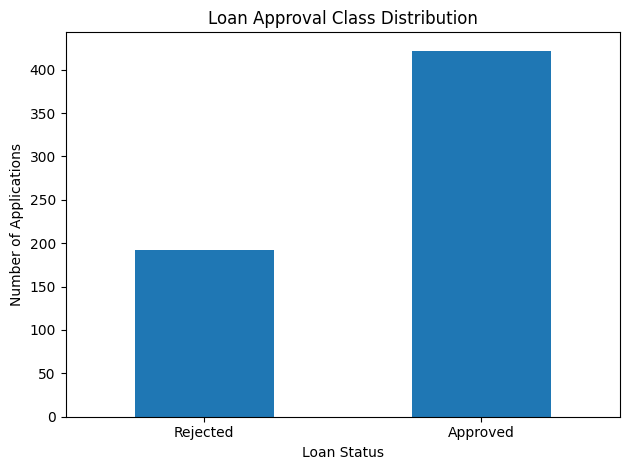

In [11]:
class_counts = df[target_col].value_counts().sort_index()

print("0 = Rejected, 1 = Approved")
print(class_counts)

print("\nClass percentages:")
print((df[target_col].value_counts(normalize=True) * 100).round(2))

class_counts.rename({
    0: "Rejected",
    1: "Approved"
}).plot(kind="bar", rot=0)

plt.title("Loan Approval Class Distribution")
plt.xlabel("Loan Status")
plt.ylabel("Number of Applications")
plt.tight_layout()
plt.show()

Separated input features (X) and target (y)

Remove target from the input features

In [12]:
X = df.drop(columns=[target_col]).copy()
y = df[target_col].astype(int)

# Remove identifier columns because IDs do not describe borrower risk
id_cols = [
    col for col in X.columns
    if col in ["loan_id", "id", "application_id", "applicant_id"]
]

X = X.drop(columns=id_cols)

# Convert numeric-looking text columns to numbers where possible
for col in X.columns:
    if X[col].dtype == "object":
        converted = pd.to_numeric(X[col], errors="coerce")
        if converted.notna().sum() > 0.9 * X[col].notna().sum():
            X[col] = converted

print("Input features:", X.shape)
print("Target:", y.shape)
print("Features used:", X.columns.tolist())


Input features: (614, 12)
Target: (614,)
Features used: ['gender', 'married', 'dependents', 'education', 'self_employed', 'applicantincome', 'coapplicantincome', 'loanamount', 'loan_amount_term', 'credit_history', 'property_area', 'property_area_fixed']


Split the data into training and testing sets

In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])


Training records: 491
Testing records: 123


Identify numerical and categorical columns

In [14]:
numeric_cols = X_train.select_dtypes(
    include=["number", "bool"]
).columns.tolist()

categorical_cols = X_train.select_dtypes(
    exclude=["number", "bool"]
).columns.tolist()

print("Numerical columns:", numeric_cols)
print("Categorical columns:", categorical_cols)

# Numerical preprocessing:
# Fill missing values using median and standardize features
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

Numerical columns: ['education', 'coapplicantincome', 'loanamount', 'loan_amount_term', 'credit_history', 'property_area']
Categorical columns: ['gender', 'married', 'dependents', 'self_employed', 'applicantincome', 'property_area_fixed']


Define the classification models

In [16]:
# Define the categorical pipeline
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

# Combine numerical and categorical pipelines into a single preprocessor
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_pipeline, numeric_cols),
    ("cat", categorical_pipeline, categorical_cols)
])

models = {
    "Logistic Regression": LogisticRegression(
        class_weight="balanced",
        max_iter=2000,
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )
}

# Train and evaluate each model
results = []
trained_models = {}
probabilities = {}

for name, model in models.items():

    # Preprocessing and model training in one pipeline
    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)

    # Predictions on unseen test data
    y_pred = pipeline.predict(X_test)
    y_prob = pipeline.predict_proba(X_test)[:, 1]

    # Calculate evaluation metrics
    results.append({
        "Model": name,
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

    trained_models[name] = pipeline
    probabilities[name] = y_prob

# Display the results
results_df = pd.DataFrame(results)
print(results_df.to_string(index=False))
print("\nAll models trained successfully!")

              Model  Precision   Recall  F1-Score  ROC-AUC
Logistic Regression   0.858696 0.929412  0.892655 0.851393
      Decision Tree   0.875000 0.741176  0.802548 0.752167
      Random Forest   0.846939 0.976471  0.907104 0.782043

All models trained successfully!


Compare all models

In [17]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="F1-Score",
    ascending=False
).reset_index(drop=True)

display(results_df.round(4))

,Model,Precision,Recall,F1-Score,ROC-AUC
0,Random Forest,0.8469,0.9765,0.9071,0.7820
1,Logistic Regression,0.8587,0.9294,0.8927,0.8514
2,Decision Tree,0.8750,0.7412,0.8025,0.7522


Select the best model based on F1-score

Best model by F1-score: Random Forest

Classification Report:
              precision    recall  f1-score   support

    Rejected       0.92      0.58      0.71        38
    Approved       0.84      0.98      0.90        85

    accuracy                           0.85       123
   macro avg       0.88      0.78      0.81       123
weighted avg       0.86      0.85      0.84       123

ROC-AUC: 0.782


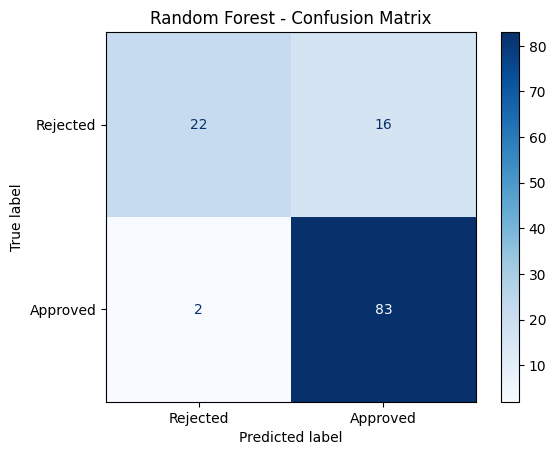

In [20]:
best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]
best_prob = probabilities[best_model_name]

print("Best model by F1-score:", best_model_name)

# Evaluate at the default threshold of 0.50
best_pred = (best_prob >= 0.50).astype(int)

print("\nClassification Report:")
print(classification_report(
    y_test,
    best_pred,
    labels=[0, 1],
    target_names=["Rejected", "Approved"],
    zero_division=0
))

print("ROC-AUC:", round(
    roc_auc_score(y_test, best_prob), 4
))

# Display confusion matrix
cm = confusion_matrix(y_test, best_pred, labels=[0, 1])

display(
    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Rejected", "Approved"]
    ).plot(cmap="Blues")
)

plt.title(f"{best_model_name} - Confusion Matrix")
plt.show()


Comparing precision and recall at different thresholds

In [19]:
thresholds = [0.30, 0.40, 0.50, 0.60, 0.70]

threshold_results = []

for threshold in thresholds:

    threshold_pred = (best_prob >= threshold).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_test, threshold_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, threshold_pred, zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, threshold_pred, zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)
display(threshold_df.round(4))


,Threshold,Precision,Recall,F1-Score
0,0.3,0.7179,0.9882,0.8317
1,0.4,0.8058,0.9765,0.8830
2,0.5,0.8384,0.9765,0.9022
3,0.6,0.8404,0.9294,0.8827
4,0.7,0.8506,0.8706,0.8605
